Telecom Churn Prediction

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("Telcom-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
df["TotalCharges"].unique()

<StringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',
 ...
 '2625.25', '6886.25',  '1495.1',   '743.3',  '1419.4',  '1990.5',  '7362.9',
  '346.45',   '306.6',  '6844.5']
Length: 6531, dtype: str

In [9]:
df["TotalCharges"]=df["TotalCharges"].replace(" ",np.nan,inplace=True)

C:\Users\himan\AppData\Local\Temp\ipykernel_16752\3962241757.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["TotalCharges"]=df["TotalCharges"].replace(" ",np.nan,inplace=True)


In [10]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")

In [11]:
#Duplicate values
df.duplicated().sum()

np.int64(0)

In [12]:
#Check missing Values
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [13]:
df[df["TotalCharges"].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


<Axes: >

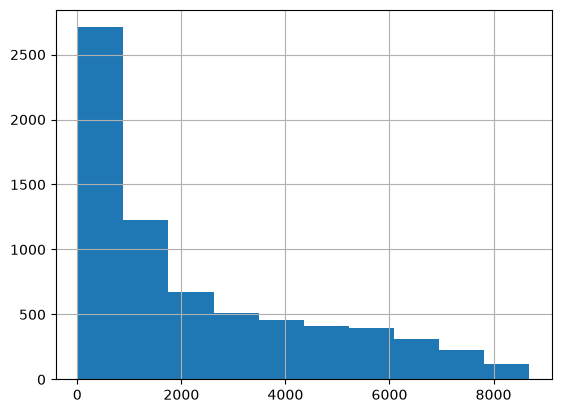

In [14]:
df["TotalCharges"].hist()

imputation technique

In [15]:
#as there is right skewness we have fill null value with median
median=df["TotalCharges"].median()

In [16]:
df["TotalCharges"]=df["TotalCharges"].fillna(median,inplace=True)

C:\Users\himan\AppData\Local\Temp\ipykernel_16752\1246188675.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["TotalCharges"]=df["TotalCharges"].fillna(median,inplace=True)


<Axes: ylabel='TotalCharges'>

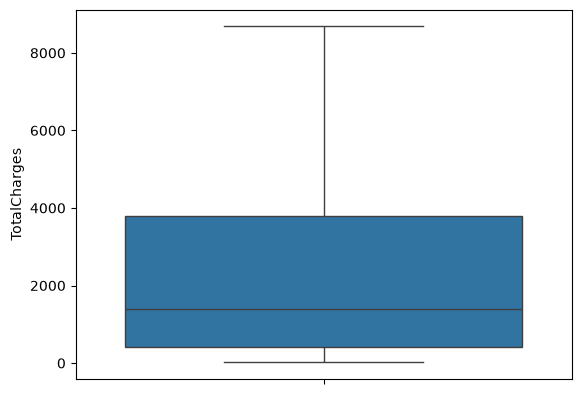

In [17]:
#find the outlires
sns.boxplot(df["TotalCharges"])

<Axes: ylabel='MonthlyCharges'>

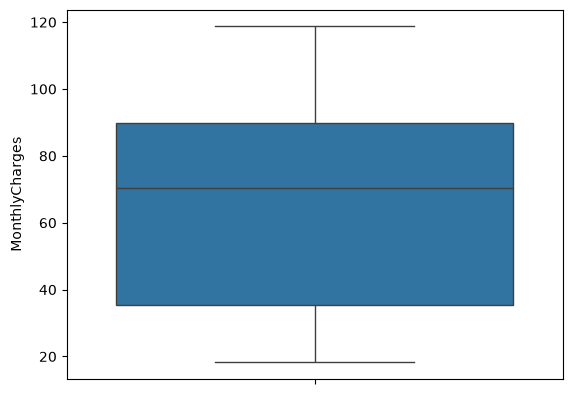

In [18]:
sns.boxplot(df["MonthlyCharges"])

In [19]:
#seperate the numerical and categorical columns
#here is numerical values
df_num = df.select_dtypes(include=["int64","float64"])
df_num

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,0,1,29.85,29.85
1,0,34,56.95,1889.50
2,0,2,53.85,108.15
3,0,45,42.30,1840.75
4,0,2,70.70,151.65
...,...,...,...,...
7038,0,24,84.80,1990.50
7039,0,72,103.20,7362.90
7040,0,11,29.60,346.45
7041,1,4,74.40,306.60


In [20]:
#here is categorical values
df_cat=df.select_dtypes(str)
df_cat

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,7590-VHVEG,Female,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,No
1,5575-GNVDE,Male,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,No
2,3668-QPYBK,Male,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,Yes
3,7795-CFOCW,Male,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),No
4,9237-HQITU,Female,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,Yes,Yes,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,No
7039,2234-XADUH,Female,Yes,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),No
7040,4801-JZAZL,Female,Yes,Yes,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
7041,8361-LTMKD,Male,Yes,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,Yes


Encoding

In [21]:
from sklearn.preprocessing import LabelEncoder 
le = LabelEncoder()

In [22]:
#converting categorical values to numeriacl values
for i in df_cat:
    df_cat[i]=le.fit_transform(df_cat[i])

In [23]:
df_cat

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,5375,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0
1,3962,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0
2,2564,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,1
3,5535,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0
4,6511,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,4853,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0
7039,1525,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0
7040,3367,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0
7041,5934,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,1


In [24]:
df_cat=df_cat.drop(columns="customerID")

In [25]:
df_cat

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0
1,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0
2,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,1
3,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0
4,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0
7039,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0
7040,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0
7041,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,1


In [26]:
#combine numerical and categorical part
df_new = pd.concat([df_num,df_cat],axis=1)
df_new

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,0,1,29.85,29.85,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0
2,0,2,53.85,108.15,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84.80,1990.50,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0
7039,0,72,103.20,7362.90,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0
7040,0,11,29.60,346.45,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0
7041,1,4,74.40,306.60,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,1


In [27]:
#splitting our dataset into independent and dependent
X=df_new.drop("Churn",axis=1)
y=df_new["Churn"]

In [28]:
X

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
0,0,1,29.85,29.85,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2
1,0,34,56.95,1889.50,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3
2,0,2,53.85,108.15,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3
3,0,45,42.30,1840.75,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0
4,0,2,70.70,151.65,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84.80,1990.50,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3
7039,0,72,103.20,7362.90,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1
7040,0,11,29.60,346.45,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2
7041,1,4,74.40,306.60,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3


In [29]:
y

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

In [30]:
#splitting the dataset into yraining and testing
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.30,random_state=42)

In [31]:
print(X_train.shape,y_train.shape)

(4930, 19) (4930,)


In [32]:
print(X_test.shape,y_test.shape)

(2113, 19) (2113,)


Scaling

In [33]:
#Min Max Scalar
from sklearn.preprocessing import MinMaxScaler

In [34]:
mm=MinMaxScaler()

In [35]:
X_train=mm.fit_transform(X_train)
X_test=mm.transform(X_test)

In [36]:
X_train

array([[0.        , 0.75      , 0.52267065, ..., 0.5       , 1.        ,
        0.66666667],
       [0.        , 0.01388889, 0.62082711, ..., 0.        , 1.        ,
        0.66666667],
       [0.        , 0.18055556, 0.01046338, ..., 0.5       , 0.        ,
        0.33333333],
       ...,
       [0.        , 0.16666667, 0.02889885, ..., 0.        , 1.        ,
        0.66666667],
       [1.        , 0.16666667, 0.80916791, ..., 0.        , 1.        ,
        0.66666667],
       [0.        , 0.36111111, 0.01544594, ..., 0.5       , 0.        ,
        0.33333333]], shape=(4930, 19))

In [37]:
X_test

array([[0.        , 0.01388889, 0.06527155, ..., 0.        , 1.        ,
        0.66666667],
       [0.        , 0.56944444, 0.06975585, ..., 0.        , 1.        ,
        0.        ],
       [0.        , 0.72222222, 0.01096163, ..., 1.        , 0.        ,
        1.        ],
       ...,
       [0.        , 0.83333333, 0.42102641, ..., 1.        , 0.        ,
        0.        ],
       [0.        , 0.27777778, 0.72197309, ..., 0.        , 1.        ,
        0.33333333],
       [0.        , 0.30555556, 0.32735426, ..., 0.        , 1.        ,
        0.66666667]], shape=(2113, 19))

Algorithm

Logistic Regression

In [38]:
from sklearn.linear_model import LogisticRegression

In [39]:
lg=LogisticRegression(max_iter=1000)

In [40]:
lg.fit(X_train,y_train)
y_pred = lg.predict(X_test)

In [41]:
y_pred

array([1, 0, 0, ..., 0, 1, 0], shape=(2113,))

In [42]:
compare= pd.DataFrame({"Actual Value":y_test,"Predicted value":y_pred})

In [43]:
compare

,Actual Value,Predicted value
185,1,1
2715,0,0
3825,0,0
1807,1,1
132,0,0
...,...,...
5522,1,1
6377,1,1
5500,0,0
2392,0,1


Model Evaluation

In [44]:
#confusion matrix-----evaluate the preformance of the a classification model
#Accuracy-----how much % prediction is correct---------(TP+TN)/(TP+TN_FP+FN)
#Precision-----predicted as positive,how much are actually positive---------TP/(TP+FP)
#Recall-----actually positive , how much model correctly identify------------TP/(TP+FN)
#F1-Score-----balanced score between precision and recall------------2*((Precision*Recall)/(Precision+Recall))------------Harmonic Mean
#ROC--Receiver operating characteristics
#AUC-- Area Under the Curve ---------1 = perfect, 0.9-1 = excellent, 0.8-0.9 =  very good, 0.7-0.8 = good, 0.6-0.7 = work, 0.5 = random, higher =better

In [45]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix

In [46]:
#confusion Metrics
confusion_matrix(y_test,y_pred)

array([[1389,  150],
       [ 249,  325]])

In [47]:
Accuracy=accuracy_score(y_test,y_pred)
precision=precision_score(y_test,y_pred)
Recall=recall_score(y_test,y_pred)
f1=f1_score(y_test,y_pred)

In [48]:
print("Accuracy Score",Accuracy)
print("Precision Score",precision)
print("Recall Score",Recall)
print("F1 Score",f1)

Accuracy Score 0.8111689540937056
Precision Score 0.6842105263157895
Recall Score 0.5662020905923345
F1 Score 0.6196377502383222


In [49]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1539
           1       0.68      0.57      0.62       574

    accuracy                           0.81      2113
   macro avg       0.77      0.73      0.75      2113
weighted avg       0.80      0.81      0.81      2113



In [50]:
!pip install imblearn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\himan\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


SMOTE

In [51]:
#SMOTE Technique
from imblearn.over_sampling import SMOTE

In [52]:
smote=SMOTE(random_state=42)

In [53]:
X_train_resample,y_train_resample=smote.fit_resample(X_train,y_train)

In [54]:
X_train_resample.shape

(7270, 19)

In [55]:
y_train_resample

0       0
1       0
2       0
3       0
4       0
       ..
7265    1
7266    1
7267    1
7268    1
7269    1
Name: Churn, Length: 7270, dtype: int64

In [56]:
y_train_resample.value_counts()

Churn
0    3635
1    3635
Name: count, dtype: int64

In [57]:
lg.fit(X_train_resample,y_train_resample)
y_pred = lg.predict(X_test)

In [58]:
confusion_matrix(y_test,y_pred)

array([[1131,  408],
       [ 102,  472]])

In [59]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.92      0.73      0.82      1539
           1       0.54      0.82      0.65       574

    accuracy                           0.76      2113
   macro avg       0.73      0.78      0.73      2113
weighted avg       0.81      0.76      0.77      2113



In [60]:
from sklearn.metrics import roc_auc_score

In [61]:
#Finding the probability
y_prob = lg.predict_proba(X_test)[:,1]
y_prob

array([0.81084152, 0.1596176 , 0.0132822 , ..., 0.01484524, 0.80304142,
       0.39175078], shape=(2113,))

In [62]:
roc_auc=roc_auc_score(y_test,y_prob)
roc_auc

0.8574134070496928

<Axes: xlabel='Churn', ylabel='count'>

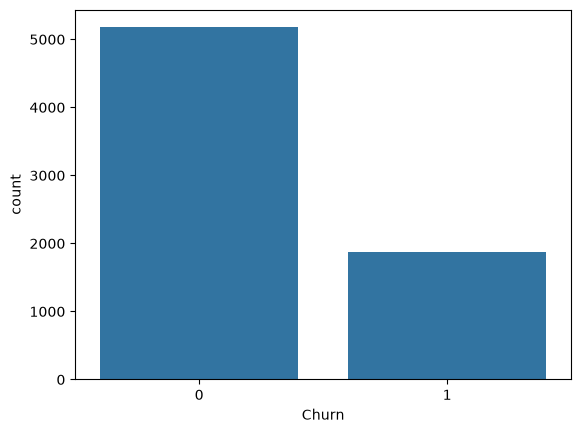

In [63]:
sns.countplot(x="Churn",data=df_new)

Text(0.5, 1.0, 'Churn Analysis')

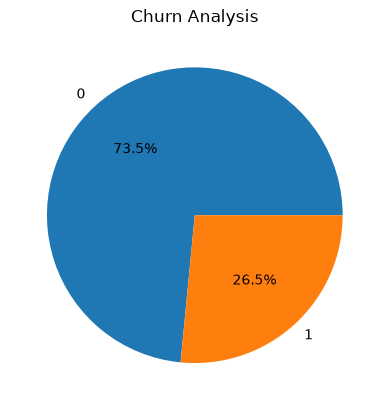

In [64]:
df_new["Churn"].value_counts().plot.pie(autopct="%1.1f%%")
plt.title("Churn Analysis")

Decision tree


In [65]:
#decision tree----root node, decision node, leaf node----puring=cutting back the branches of the tree to make it simpler
df_new

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,0,1,29.85,29.85,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0
2,0,2,53.85,108.15,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84.80,1990.50,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0
7039,0,72,103.20,7362.90,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0
7040,0,11,29.60,346.45,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0
7041,1,4,74.40,306.60,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,1


In [66]:
from sklearn.tree import DecisionTreeClassifier

In [67]:
dc= DecisionTreeClassifier(random_state=42)

In [68]:
dc.fit(X_train_resample,y_train_resample)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [69]:
y_pred=dc.predict(X_test)

In [70]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.82      0.79      0.80      1539
           1       0.49      0.53      0.51       574

    accuracy                           0.72      2113
   macro avg       0.65      0.66      0.66      2113
weighted avg       0.73      0.72      0.72      2113



In [71]:
y_prob = dc.predict_proba(X_test)[:,1]
y_prob

array([1., 0., 0., ..., 0., 0., 0.], shape=(2113,))

In [72]:
roc_auc=roc_auc_score(y_test,y_prob)
roc_auc

0.6615539526322582

In [73]:
dc.score(X_train_resample,y_train_resample)

0.9988995873452545

In [74]:
dc.score(X_test,y_test)

0.7203028868906768

In [75]:
# decision tree with max depth
dc1= DecisionTreeClassifier(max_depth=2)

In [76]:
dc1.fit(X_train_resample,y_train_resample)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [77]:
y_preddc1=dc1.predict(X_test)

In [78]:
print(classification_report(y_test,y_preddc1))

              precision    recall  f1-score   support

           0       0.88      0.74      0.80      1539
           1       0.51      0.73      0.60       574

    accuracy                           0.74      2113
   macro avg       0.70      0.74      0.70      2113
weighted avg       0.78      0.74      0.75      2113



In [79]:
dc2= DecisionTreeClassifier(max_depth=2)
dc2.fit(X_train,y_train)
y_preddc2=dc2.predict(X_test)

In [80]:
print(classification_report(y_test,y_preddc2))

              precision    recall  f1-score   support

           0       0.88      0.74      0.80      1539
           1       0.51      0.73      0.60       574

    accuracy                           0.74      2113
   macro avg       0.70      0.74      0.70      2113
weighted avg       0.78      0.74      0.75      2113



In [81]:
from sklearn.tree import plot_tree

[Text(0.5, 0.8333333333333334, '[0.00000000e+00 1.38888889e-02 2.14250125e-02 1.84629587e-04\n 0.00000000e+00 0.00000000e+00 0.00000000e+00 1.00000000e+00\n 0.00000000e+00 1.00000000e+00 5.00000000e-01 5.00000000e-01\n 5.00000000e-01 5.00000000e-01 5.00000000e-01 5.00000000e-01\n 0.00000000e+00 0.00000000e+00 1.00000000e+00] <= 0.5\ngini = 0.5\nsamples = 7270\nvalue = [3635, 3635]\nclass = NO'),
 Text(0.25, 0.5, '[1.         0.86111111 0.85201794 0.73442765 1.         1.\n 0.         1.         1.         0.5        0.         1.\n 1.         0.         1.         1.         0.5        1.\n 0.66666667] <= 0.499\ngini = 0.434\nsamples = 4881\nvalue = [1553, 3328]\nclass = Yes'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.371\nsamples = 3605\nvalue = [888, 2717]\nclass = Yes'),
 Text(0.375, 0.16666666666666666, 'gini = 0.499\nsamples = 1276\nvalue = [665, 611]\nclass = NO'),
 Text(0.75, 0.5, '[0.         0.18055556 0.01046338 0.02779252 1.    

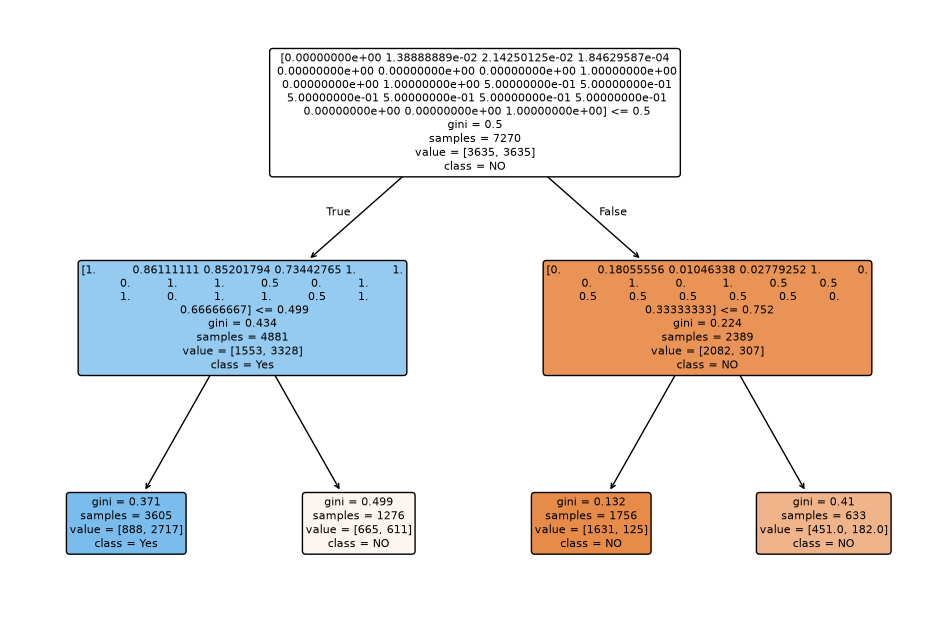

In [82]:
plt.figure(figsize=(12,8))
plot_tree(
    dc1,feature_names=X_train_resample,
    class_names=["NO","Yes"],
                 filled=True,
                 fontsize=8,
                 rounded=True
)

Random Forest

In [83]:
# most accurate,voiting system almost eliminates overfitting-----require more memory and processing power

In [84]:
from sklearn.ensemble import RandomForestClassifier

In [85]:
rf=RandomForestClassifier(n_estimators=100,random_state=42)

In [86]:
rf.fit(X_train_resample,y_train_resample)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [87]:
y_pred_rf = rf.predict(X_test)
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1539
           1       0.60      0.60      0.60       574

    accuracy                           0.78      2113
   macro avg       0.72      0.72      0.72      2113
weighted avg       0.78      0.78      0.78      2113



In [88]:
y_prob_rf = rf.predict_proba(X_test)[:,1]
y_prob_rf

array([0.68, 0.12, 0.  , ..., 0.1 , 0.42, 0.2 ], shape=(2113,))

In [89]:
roc_auc=roc_auc_score(y_test,y_prob_rf)
roc_auc

0.8355967832861285

In [90]:
confusion_matrix(y_test,y_pred_rf)

array([[1309,  230],
       [ 231,  343]])

Support Vector Machine(SVM)

In [91]:
#hyperplane--- center line
#margin---the distance between the hyperplane  and nearest data points ---keep it as wide as possible
#Support vector--- data points at the edge of margin
#linear svm and non-linear svm(2D to 3D)


In [92]:
from sklearn.svm import SVC

In [93]:
sv=SVC(kernel="rbf",random_state=42,probability=True)

In [94]:
sv.fit(X_train_resample,y_train_resample)

C:\Users\himan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [95]:
y_pred_sv = sv.predict(X_test)
print(classification_report(y_test, y_pred_sv))

              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1539
           1       0.55      0.71      0.62       574

    accuracy                           0.76      2113
   macro avg       0.71      0.75      0.72      2113
weighted avg       0.79      0.76      0.77      2113



In [96]:
y_prob_sv = rf.predict_proba(X_test)[:,1]
y_prob_sv

array([0.68, 0.12, 0.  , ..., 0.1 , 0.42, 0.2 ], shape=(2113,))

In [97]:
roc_auc=roc_auc_score(y_test,y_prob_sv)
roc_auc

0.8355967832861285

Model Evaluation

In [98]:
#Cross Validation----
from imblearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold
from sklearn.model_selection import cross_validate

In [99]:
lg_pipeline= Pipeline([
    ("scaler",MinMaxScaler()),
    ("smote",SMOTE(random_state=42)),
    ("model",LogisticRegression(max_iter=1000))
])

In [100]:
#cross validation

cv=StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42)

In [101]:
score = cross_validate(
    lg_pipeline,
    X_train,                 
    y_train,                 
    cv=cv,
    scoring=["accuracy","precision","recall","f1","roc_auc"],
    return_train_score=False
)

In [102]:
After_cv=pd.DataFrame({"Accuracy":score["test_accuracy"],
           "Precision": score["test_precision"],
           "recall" :score["test_recall"],
           "F1 Score" :score["test_f1"],
           "roc_auc" :score["test_roc_auc"]})
After_cv.mean().round(3)

Accuracy     0.740
Precision    0.504
recall       0.783
F1 Score     0.613
roc_auc      0.836
dtype: float64

In [103]:
from imblearn.pipeline import Pipeline

#Step1---create pipeline
rf_pipeline= Pipeline([
    ("scaler",MinMaxScaler()),
    ("smote",SMOTE(random_state=42)),
    ("model",RandomForestClassifier(random_state=42,n_jobs=1))
])

In [104]:

#step 2 -----Define parameter grid
param_grid_rf = {
    "model__n_estimators": [100, 200],
    "model__criterion": ['gini', 'entropy'],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

In [105]:
#Step 3------cross validation
cv_rf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [106]:
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
#Step 4-----Hyperparameter Tunning
grid_search_rf = GridSearchCV(
    estimator= rf_pipeline,
    param_grid= param_grid_rf,
    cv= cv_rf,
    scoring="f1",
    n_jobs=-1
)

#Step 5----Training the dataset
grid_search_rf.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__criterion': ['gini', 'entropy'], 'model__max_depth': [5, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... version

In [107]:
#Step 6---- Best Parameter
grid_search_rf.best_params_

{'model__criterion': 'gini',
 'model__max_depth': 10,
 'model__min_samples_leaf': 2,
 'model__min_samples_split': 5,
 'model__n_estimators': 100}

In [108]:
grid_search_rf.best_score_

np.float64(0.6273723229428758)

In [109]:
best_estimator=grid_search_rf.best_estimator_
best_estimator

,steps,"[('scaler', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
n_features_in_,int,19
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value


In [110]:
y_pred_rf_et = best_estimator.predict(X_test)
y_pred_rf_et

array([1, 0, 0, ..., 0, 1, 0], shape=(2113,))

In [111]:
confusion_matrix(y_test, y_pred_rf_et)

array([[1231,  308],
       [ 152,  422]])

In [112]:
print(classification_report(y_test, y_pred_rf_et))

              precision    recall  f1-score   support

           0       0.89      0.80      0.84      1539
           1       0.58      0.74      0.65       574

    accuracy                           0.78      2113
   macro avg       0.73      0.77      0.74      2113
weighted avg       0.81      0.78      0.79      2113



Bagging and Boosting Technique

In [113]:
from sklearn.ensemble import (GradientBoostingClassifier,AdaBoostClassifier,BaggingClassifier,)

In [114]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

In [115]:
bagging_model=BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
    )

#Train
bagging_model.fit(X_train,y_train)

#Predict
y_pred_bagg=bagging_model.predict(X_test)
y_prob_bagg=bagging_model.predict_proba(X_test)[:,1]

#Evaluate

print(classification_report(y_test,y_pred_bagg))
print("ROC-Auc:",roc_auc_score(y_test,y_prob_bagg))
print("Bagging Accuracy:",accuracy_score(y_test,y_pred_bagg))

              precision    recall  f1-score   support

           0       0.82      0.90      0.86      1539
           1       0.63      0.49      0.55       574

    accuracy                           0.78      2113
   macro avg       0.73      0.69      0.70      2113
weighted avg       0.77      0.78      0.77      2113

ROC-Auc: 0.8244997090739495
Bagging Accuracy: 0.7841930903928065


Boosting


In [116]:
# Adaboost
ada_boost=AdaBoostClassifier(
    estimator=RandomForestClassifier(random_state=42),
    n_estimators=200,
    random_state=42,
    learning_rate=1,
)

#Traing the model

ada_boost.fit(X_train,y_train)

#Prediction
y_pred_ada=ada_boost.predict(X_test)
y_prob_ada=ada_boost.predict_proba(X_test)[:,-1]


print(classification_report(y_test,y_pred_ada))
print("ROC-Auc:",roc_auc_score(y_test,y_prob_ada))
print("Boosting Accuracy:",accuracy_score(y_test,y_pred_ada))

              precision    recall  f1-score   support

           0       0.82      0.91      0.87      1539
           1       0.67      0.48      0.56       574

    accuracy                           0.79      2113
   macro avg       0.75      0.69      0.71      2113
weighted avg       0.78      0.79      0.78      2113

ROC-Auc: 0.7975381090485927
Boosting Accuracy: 0.7931850449597728


In [117]:
# Gradient Boost 
gradient_boost=GradientBoostingClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=5,
    learning_rate=0.1,

)

#Training
gradient_boost.fit(X_train,y_train)

#Prediction
y_pred_gb=gradient_boost.predict(X_test)
y_prob_gb=gradient_boost.predict_proba(X_test)[:,-1]

#Evaluate

print(classification_report(y_test,y_pred_gb))
print("ROC-Auc:",roc_auc_score(y_test,y_prob_gb))
print("Gradient Boosting Accuracy:",accuracy_score(y_test,y_pred_gb))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1539
           1       0.65      0.49      0.56       574

    accuracy                           0.79      2113
   macro avg       0.74      0.70      0.71      2113
weighted avg       0.78      0.79      0.78      2113

ROC-Auc: 0.8464555698188562
Gradient Boosting Accuracy: 0.7889256980596309


In [118]:
#  xGBoost
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.2 MB/s eta 0:00:41
    --------------------------------------- 0.8/48.9 MB 1.2 MB/s eta 0:00:40
    --------------------------------------- 1.0/48.9 MB 1.2 MB/s eta 0:00:40
   - -------------------------------------- 1.3/48.9 MB 1.2 MB/s eta 0:00:40
   - -------------------------------------- 1.6/48.9 MB 1.2 MB/s eta 0:00:40
   - -------------------------------------- 1.8/48.9 MB 1.2 MB/s eta 0:00:41
   - -------------------------------------- 2.1/48.9 MB 1.2 MB/s eta 0:00:39
   - -------------------------------------- 2.4/48.9 MB 1.2 MB/s eta 0:00:39
   -- ------------------------------------- 2.6/48.9 MB 1.2 MB/s eta 0:00:39
   -- ------------------------------------- 2.9/48.9 MB 1.2 MB/s eta 0:00:39
   -- --------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\himan\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [119]:
from xgboost import XGBClassifier

xgb_boost = XGBClassifier(
    n_estimators=200,
    random_state=42,
    learning_rate=0.1,
    max_depth=5
)

#Training

xgb_boost.fit(X_train,y_train)

#Prediction
y_pred_xgb=xgb_boost.predict(X_test)
y_prob_xgb=xgb_boost.predict_proba(X_test)[:,-1]

#Evaluate
print("xgb Boosting Accuracy:",accuracy_score(y_test,y_pred_xgb))
print(classification_report(y_test,y_pred_xgb))
print("ROC-Auc:",roc_auc_score(y_test,y_prob_xgb))

xgb Boosting Accuracy: 0.8031235210601041
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1539
           1       0.67      0.55      0.60       574

    accuracy                           0.80      2113
   macro avg       0.75      0.72      0.74      2113
weighted avg       0.79      0.80      0.80      2113

ROC-Auc: 0.8491050344922829


In [121]:
from xgboost import XGBClassifier

xgb_boost = XGBClassifier(
    n_estimators=100,
    random_state=42,
    learning_rate=0.1,
    max_depth=5,
    eval_metric="logloss",        #parameter=eval_metric=logloss
)

#Training

xgb_boost.fit(X_train,y_train)

#Prediction
y_pred_xgb=xgb_boost.predict(X_test)
y_prob_xgb=xgb_boost.predict_proba(X_test)[:,-1]

#Evaluate
print("xgb Boosting Accuracy:",accuracy_score(y_test,y_pred_xgb))
print(classification_report(y_test,y_pred_xgb))
print("ROC-Auc:",roc_auc_score(y_test,y_prob_xgb))

xgb Boosting Accuracy: 0.8021769995267393
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1539
           1       0.67      0.53      0.59       574

    accuracy                           0.80      2113
   macro avg       0.75      0.72      0.73      2113
weighted avg       0.79      0.80      0.79      2113

ROC-Auc: 0.8545165986329872
